In [1]:
import sys
from importlib.metadata import PackageNotFoundError, version

print("Python executable:", sys.executable)

for package in ("torch", "torchvision", "timm"):
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Python executable: C:\Users\HP\miniconda3\envs\brainxai-train\python.exe
torch: 2.9.1+cu126
torchvision: 0.24.1+cu126
timm: not installed


In [2]:
%pip install --dry-run timm

  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Would install PyYAML-6.0.3 anyio-4.16.0 click-8.5.1 h11-0.16.0 hf-xet-1.8.0 httpcore2-2.16.0 httpx2-2.16.0 huggingface_hub-2.4.0 idna-3.20 safetensors-0.8.0 timm-1.0.31 tqdm-4.70.1 truststore-0.10.5
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install timm==1.0.31

  Using cached timm-1.0.31-py3-none-any.whl.metadata (42 kB)
  Using cached pyyaml-6.0.3-cp311-cp311-win_amd64.whl.metadata (2.4 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.8/2.8 MB 4.8 MB/s eta 0:00:01
 

In [1]:
import torch
import torchvision
import timm

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.9.1+cu126
Torchvision: 0.24.1+cu126
timm: 1.0.31
CUDA available: True


In [2]:
import timm

model_ids = (
    "mobilenetv4_conv_small.e2400_r224_in1k",
    "convnextv2_atto.fcmae_ft_in1k",
    "repvit_m0_9.dist_450e_in1k",
)

for model_id in model_ids:
    try:
        model = timm.create_model(model_id, pretrained=False, num_classes=4)
        parameter_count = sum(p.numel() for p in model.parameters())
        print(f"BUILT | {model_id} | {parameter_count:,} parameters")
        del model
    except Exception as error:
        print(f"FAILED | {model_id} | {type(error).__name__}: {error}")

BUILT | mobilenetv4_conv_small.e2400_r224_in1k | 2,498,148 parameters
BUILT | convnextv2_atto.fcmae_ft_in1k | 3,388,684 parameters
BUILT | repvit_m0_9.dist_450e_in1k | 4,722,408 parameters


In [3]:
import torch
import timm

print("GPU:", torch.cuda.get_device_name(0))

def check_gpu_forward(model_id):
    torch.cuda.reset_peak_memory_stats()

    model = timm.create_model(model_id, pretrained=False, num_classes=4)
    model = model.to("cuda").eval()

    with torch.inference_mode():
        sample = torch.ones((1, 3, 224, 224), device="cuda")
        scores = model(sample)

    shape = tuple(scores.shape)
    finite = torch.isfinite(scores).all().item()
    peak_mib = torch.cuda.max_memory_allocated() / (1024 ** 2)
    status = "PASS" if shape == (1, 4) and finite else "FAIL"

    print(f"{status} | {model_id} | shape={shape} | finite={finite} "
          f"| peak allocated={peak_mib:.1f} MiB")

for model_id in model_ids:
    try:
        check_gpu_forward(model_id)
    except Exception as error:
        print(f"FAIL | {model_id} | {type(error).__name__}: {error}")

GPU: NVIDIA GeForce GTX 1650
PASS | mobilenetv4_conv_small.e2400_r224_in1k | shape=(1, 4) | finite=True | peak allocated=19.6 MiB
PASS | convnextv2_atto.fcmae_ft_in1k | shape=(1, 4) | finite=True | peak allocated=29.8 MiB
PASS | repvit_m0_9.dist_450e_in1k | shape=(1, 4) | finite=True | peak allocated=32.3 MiB


In [4]:
import csv
from pathlib import Path

project_root = Path(r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI")
dataset_root = project_root / "data" / "raw" / "brisc2025"
manifest_dir = project_root / "data" / "processed"

records = {}

for split, expected in (("train", 3889), ("validation", 973)):
    manifest_path = manifest_dir / f"classification_{split}_manifest.csv"

    with manifest_path.open(encoding="utf-8-sig", newline="") as file:
        rows = list(csv.DictReader(file))

    missing = [
        row["relative_path"] for row in rows
        if not (dataset_root / row["relative_path"]).is_file()
    ]

    records[split] = rows
    status = "PASS" if len(rows) == expected and not missing else "CHECK"
    print(f"{status} | {split} | rows={len(rows)} | missing files={len(missing)}")

    if missing:
        print("First missing path:", dataset_root / missing[0])

PASS | train | rows=3889 | missing files=0
PASS | validation | rows=973 | missing files=0


In [5]:
import torch
from PIL import Image
from torchvision.transforms.functional import pil_to_tensor

def load_canonical_mri(path):
    with Image.open(path) as image:
        gray = image.convert("L")
        resized = gray.resize((224, 224), Image.Resampling.BILINEAR)

    # One grayscale channel, scaled from 0–255 to 0–1
    tensor = pil_to_tensor(resized).to(torch.float32) / 255.0

    # Give the CNN three identical copies of that channel
    return tensor.repeat(3, 1, 1)

row = records["validation"][0]
mri = load_canonical_mri(dataset_root / row["relative_path"])

low, high = mri.min().item(), mri.max().item()
channels_match = torch.equal(mri[0], mri[1]) and torch.equal(mri[1], mri[2])

print("File:", row["relative_path"])
print("Manifest label:", row["tumor_label"])
print("Shape:", tuple(mri.shape), "| dtype:", mri.dtype)
print(f"Intensity range: {low:.4f} to {high:.4f}")
print("All three channels identical:", channels_match)

assert mri.shape == (3, 224, 224)
assert mri.dtype == torch.float32
assert 0.0 <= low <= high <= 1.0
assert channels_match
print("PASS | canonical MRI tensor")

File: classification_task\train\glioma\brisc2025_train_00903_gl_sa_t1.jpg
Manifest label: glioma
Shape: (3, 224, 224) | dtype: torch.float32
Intensity range: 0.0000 to 0.9137
All three channels identical: True
PASS | canonical MRI tensor


In [6]:
from torch.utils.data import Dataset, DataLoader

class_to_index = {
    "glioma": 0,
    "meningioma": 1,
    "no_tumor": 2,
    "pituitary": 3,
}

# Verify the label spellings against both frozen development manifests.
for split in ("train", "validation"):
    labels = {row["tumor_label"] for row in records[split]}
    assert labels == set(class_to_index), f"Unexpected labels in {split}: {labels}"


class BRISCClassificationDataset(Dataset):
    def __init__(self, rows, root, label_map):
        self.rows = rows
        self.root = root
        self.label_map = label_map

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = load_canonical_mri(self.root / row["relative_path"])
        label = self.label_map[row["tumor_label"]]
        return image, label


validation_dataset = BRISCClassificationDataset(
    records["validation"], dataset_root, class_to_index
)

# Keep manifest order so the first image matches the one you just checked.
validation_loader = DataLoader(
    validation_dataset, batch_size=4, shuffle=False, num_workers=0
)

images, targets = next(iter(validation_loader))

print("Validation dataset size:", len(validation_dataset))
print("Image batch:", tuple(images.shape), "|", images.dtype)
print("Label batch:", targets.tolist(), "|", targets.dtype)

expected_targets = [
    class_to_index[row["tumor_label"]] for row in records["validation"][:4]
]
assert len(validation_dataset) == 973
assert images.shape == (4, 3, 224, 224)
assert targets.dtype == torch.long
assert targets.tolist() == expected_targets
assert torch.equal(images[0], mri)
print("PASS | validation batch matches the manifest and the checked MRI")

Validation dataset size: 973
Image batch: (4, 3, 224, 224) | torch.float32
Label batch: [0, 3, 3, 3] | torch.int64
PASS | validation batch matches the manifest and the checked MRI


In [7]:
from timm.models import get_pretrained_cfg

normalization_by_model = {}

for model_id in model_ids:
    cfg = get_pretrained_cfg(model_id)

    if cfg is None or cfg.mean is None or cfg.std is None:
        raise ValueError(f"Missing normalization metadata for {model_id}")

    mean, std = tuple(cfg.mean), tuple(cfg.std)
    assert len(mean) == len(std) == 3, f"Expected three channels for {model_id}"
    assert all(value > 0 for value in std), f"Invalid standard deviation for {model_id}"

    normalization_by_model[model_id] = {"mean": mean, "std": std}

    print(model_id)
    print("  Input size:", cfg.input_size)
    print("  Mean:", mean)
    print("  Std: ", std)

mobilenetv4_conv_small.e2400_r224_in1k
  Input size: (3, 224, 224)
  Mean: (0.485, 0.456, 0.406)
  Std:  (0.229, 0.224, 0.225)
convnextv2_atto.fcmae_ft_in1k
  Input size: (3, 224, 224)
  Mean: (0.485, 0.456, 0.406)
  Std:  (0.229, 0.224, 0.225)
repvit_m0_9.dist_450e_in1k
  Input size: (3, 224, 224)
  Mean: (0.485, 0.456, 0.406)
  Std:  (0.229, 0.224, 0.225)


In [8]:
from torchvision.transforms.functional import normalize

# Confirm that one shared configuration applies to every selected model.
shared_norm = normalization_by_model[model_ids[0]]
assert all(normalization_by_model[mid] == shared_norm for mid in model_ids)

mean = shared_norm["mean"]
std = shared_norm["std"]

# Keep the canonical [0, 1] batch available for comparison.
normalized_images = normalize(images, mean=mean, std=std, inplace=False)

# Reverse the operation channel by channel: original = normalized * std + mean.
mean_tensor = images.new_tensor(mean).view(1, 3, 1, 1)
std_tensor = images.new_tensor(std).view(1, 3, 1, 1)
recovered_images = normalized_images * std_tensor + mean_tensor

print("Batch shape:", tuple(normalized_images.shape))
print("Normalized range:", normalized_images.min().item(),
      "to", normalized_images.max().item())
print("Maximum recovery error:", (recovered_images - images).abs().max().item())

assert normalized_images.shape == (4, 3, 224, 224)
assert torch.isfinite(normalized_images).all().item()
torch.testing.assert_close(recovered_images, images, rtol=0, atol=1e-6)
print("PASS | shared checkpoint normalization verified on a real MRI batch")

Batch shape: (4, 3, 224, 224)
Normalized range: -2.1179039478302 to 2.430849552154541
Maximum recovery error: 5.960464477539063e-08
PASS | shared checkpoint normalization verified on a real MRI batch


In [9]:
from torchvision.transforms import Normalize


class BRISCValidationDataset(BRISCClassificationDataset):
    def __init__(self, rows, root, label_map, normalization):
        super().__init__(rows, root, label_map)
        self.normalize = Normalize(**normalization)

    def __getitem__(self, index):
        image, label = super().__getitem__(index)
        return self.normalize(image), label


model_validation_dataset = BRISCValidationDataset(
    records["validation"], dataset_root, class_to_index, shared_norm
)

model_validation_loader = DataLoader(
    model_validation_dataset, batch_size=4, shuffle=False, num_workers=0
)

loader_images, loader_targets = next(iter(model_validation_loader))

# Compare against the manually verified batch from the previous cell.
torch.testing.assert_close(loader_images, normalized_images, rtol=0, atol=1e-6)
assert torch.equal(loader_targets, targets)

print("Validation images:", len(model_validation_dataset))
print("Model-ready batch:", tuple(loader_images.shape))
print("Labels:", loader_targets.tolist())
print("PASS | validation loader reproduces the verified normalized batch")

Validation images: 973
Model-ready batch: (4, 3, 224, 224)
Labels: [0, 3, 3, 3]
PASS | validation loader reproduces the verified normalized batch


Training file: brisc2025_train_01458_me_ax_t1.jpg | Class: meningioma
Left = original | Right = augmented | Preview seed = 42


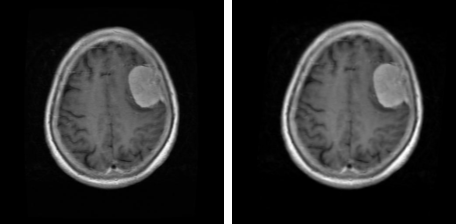

In [10]:
import json
from IPython.display import display
from PIL import Image
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from torchvision.transforms.functional import to_pil_image

config_path = manifest_dir / "brisc_preprocessing_config.json"
with config_path.open(encoding="utf-8") as file:
    aug = json.load(file)["augmentation"]

assert aug["apply_to_train_only"]
assert not aug["apply_to_validation"] and not aug["apply_to_test"]

train_augmentation = T.Compose([
    T.RandomAffine(
        degrees=tuple(aug["rotation_degrees"]),
        translate=(
            aug["translation_fraction"]["horizontal"],
            aug["translation_fraction"]["vertical"],
        ),
        scale=tuple(aug["scale_range"]),
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    T.ColorJitter(
        brightness=tuple(aug["brightness_factor_range"]),
        contrast=tuple(aug["contrast_factor_range"]),
    ),
])

row = records["train"][0]
original = load_canonical_mri(dataset_root / row["relative_path"])

# Seed only the preview. Restore the CPU random state afterward.
with torch.random.fork_rng(devices=[]):
    torch.default_generator.manual_seed(42)
    augmented = train_augmentation(original)

assert augmented.shape == original.shape
assert torch.isfinite(augmented).all()
assert 0 <= augmented.min().item() <= augmented.max().item() <= 1

# Display both images at the same intensity scale, before normalization.
before = to_pil_image(original[0])
after = to_pil_image(augmented[0])
preview = Image.new("L", (before.width * 2 + 8, before.height), color=255)
preview.paste(before, (0, 0))
preview.paste(after, (before.width + 8, 0))

print("Training file:", row["filename"], "| Class:", row["tumor_label"])
print("Left = original | Right = augmented | Preview seed = 42")
display(preview)

glioma | brisc2025_train_00973_gl_sa_t1.jpg
meningioma | brisc2025_train_01458_me_ax_t1.jpg
no_tumor | brisc2025_train_02551_no_ax_t1.jpg
pituitary | brisc2025_train_04573_pi_sa_t1.jpg


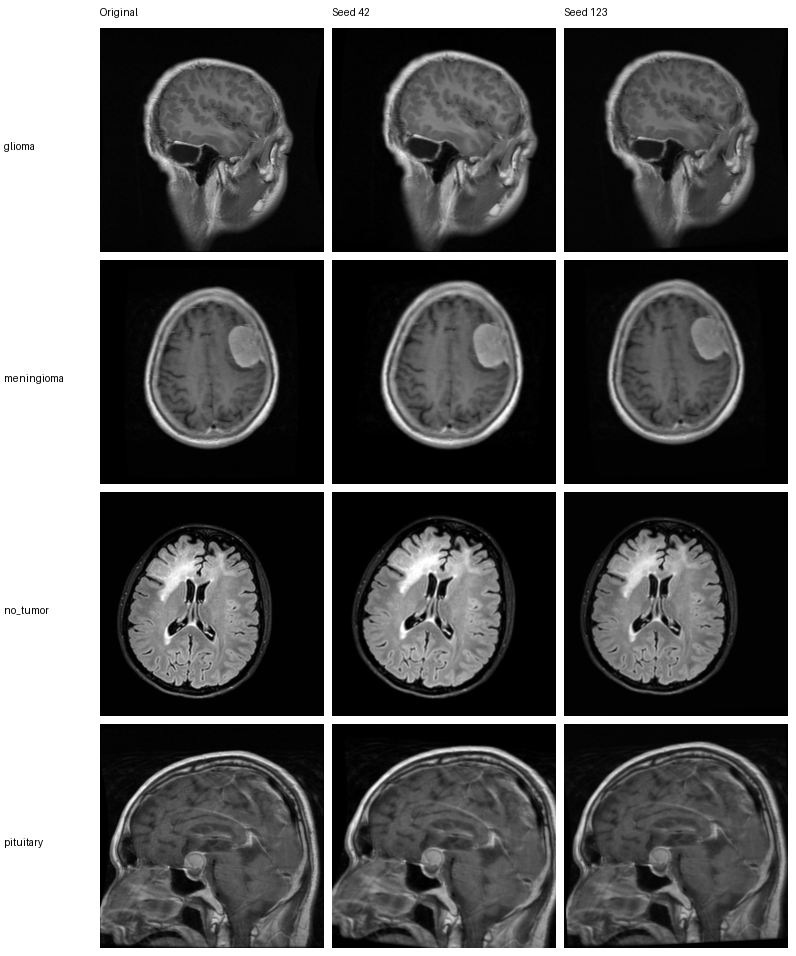

In [11]:
from PIL import ImageDraw

seeds = (42, 123)
tile = 224
label_width = 100
header_height = 28
gap = 8

grid = Image.new(
    "RGB",
    (label_width + 3 * (tile + gap), header_height + 4 * (tile + gap)),
    "white",
)
draw = ImageDraw.Draw(grid)

for col, title in enumerate(("Original", "Seed 42", "Seed 123")):
    draw.text((label_width + col * (tile + gap), 6), title, fill="black")

for row_index, label in enumerate(class_to_index):
    row = next(r for r in records["train"] if r["tumor_label"] == label)
    original = load_canonical_mri(dataset_root / row["relative_path"])
    variants = [original]

    for seed in seeds:
        with torch.random.fork_rng(devices=[]):
            torch.default_generator.manual_seed(seed)
            variants.append(train_augmentation(original))

    y = header_height + row_index * (tile + gap)
    draw.text((4, y + tile // 2), label, fill="black")

    for col, tensor in enumerate(variants):
        x = label_width + col * (tile + gap)
        grid.paste(to_pil_image(tensor[0]), (x, y))

    print(label, "|", row["filename"])

display(grid)

In [12]:
class BRISCTrainingDataset(BRISCClassificationDataset):
    def __init__(self, rows, root, label_map, augmentation, normalization):
        super().__init__(rows, root, label_map)
        self.augmentation = augmentation
        self.normalize = Normalize(**normalization)

    def __getitem__(self, index):
        image, label = super().__getitem__(index)
        return self.normalize(self.augmentation(image)), label


training_dataset = BRISCTrainingDataset(
    records["train"], dataset_root, class_to_index,
    train_augmentation, shared_norm
)

# The first training record is the meningioma scan from the first preview.
row = records["train"][0]
canonical = load_canonical_mri(dataset_root / row["relative_path"])

# Build the reference manually, then repeat the same draw through the dataset.
# The fixed seed applies only to this check.
with torch.random.fork_rng(devices=[]):
    torch.default_generator.manual_seed(42)
    expected = normalize(train_augmentation(canonical), mean=mean, std=std)

    torch.default_generator.manual_seed(42)
    actual, target = training_dataset[0]

torch.testing.assert_close(actual, expected, rtol=0, atol=1e-6)
assert target == class_to_index[row["tumor_label"]]
assert len(training_dataset) == 3889

print("Training images:", len(training_dataset))
print("Checked file:", row["filename"])
print("Label:", row["tumor_label"], "| Target:", target)
print("PASS | training dataset applies augmentation before normalization")

Training images: 3889
Checked file: brisc2025_train_01458_me_ax_t1.jpg
Label: meningioma | Target: 1
PASS | training dataset applies augmentation before normalization


In [13]:
def preview_first_training_batch(seed):
    shuffle_generator = torch.Generator().manual_seed(seed)

    # Restore the notebook's CPU random state after this preview.
    with torch.random.fork_rng(devices=[]):
        torch.default_generator.manual_seed(seed)

        loader = DataLoader(
            training_dataset,
            batch_size=4,
            shuffle=True,
            generator=shuffle_generator,
            num_workers=0,
        )
        return next(iter(loader))


batch_a, labels_a = preview_first_training_batch(42)
batch_b, labels_b = preview_first_training_batch(42)

assert batch_a.shape == (4, 3, 224, 224)
assert batch_a.dtype == torch.float32
assert torch.isfinite(batch_a).all().item()
assert labels_a.shape == (4,) and labels_a.dtype == torch.long
assert torch.equal(labels_a, labels_b), "Labels differed between runs"
assert torch.equal(batch_a, batch_b), "Augmented images differed between runs"

print("Training batch:", tuple(batch_a.shape))
print("Shuffled labels:", labels_a.tolist())
print("PASS | same seed reproduced the first shuffled and augmented batch")

Training batch: (4, 3, 224, 224)
Shuffled labels: [0, 1, 0, 1]
PASS | same seed reproduced the first shuffled and augmented batch


In [14]:
def check_validation_forward(model_id, images_cpu):
    model = timm.create_model(model_id, pretrained=False, num_classes=4)
    model = model.to("cuda").eval()

    with torch.inference_mode():
        scores = model(images_cpu.to("cuda"))

    assert scores.shape == (len(images_cpu), 4), f"Unexpected shape: {scores.shape}"
    assert torch.isfinite(scores).all().item(), "Output contains NaN or infinity"
    print(f"PASS | {model_id} | output={tuple(scores.shape)}")


validation_images, validation_targets = next(iter(model_validation_loader))
print("Validation input:", tuple(validation_images.shape))
print("Manifest targets:", validation_targets.tolist())

for model_id in model_ids:
    check_validation_forward(model_id, validation_images)

Validation input: (4, 3, 224, 224)
Manifest targets: [0, 3, 3, 3]
PASS | mobilenetv4_conv_small.e2400_r224_in1k | output=(4, 4)
PASS | convnextv2_atto.fcmae_ft_in1k | output=(4, 4)
PASS | repvit_m0_9.dist_450e_in1k | output=(4, 4)


In [15]:
from hashlib import sha256

reference_hashes = {
    "classification_train_manifest.csv":
        "a821cf5377e38116a2968512e88937b4d7e83c217c37686f546dac83b1e67716",
    "classification_validation_manifest.csv":
        "992889a407502602f56530049a9681dc26d407072697ee0ba79306e9f8bd5317",
    "classification_test_manifest.csv":
        "f0684e07e9a73d53badf47834555e3cd9058182cc8aa68b2ed73b3829b5d8183",
    "classification_final_split_manifest.csv":
        "612adcf85ddd1b6e2234b7f9e047495af76497847be5a3c4f91cda1939df4c03",
    "brisc_preprocessing_config.json":
        "d3620c7d77d5d3c454e4f7c7d058a755f3bad77e378df73cb4bd9939d4cafe90",
}

for filename, expected in reference_hashes.items():
    local_hash = sha256((manifest_dir / filename).read_bytes()).hexdigest()
    status = "MATCH" if local_hash == expected else "REVIEW"
    print(f"{status} | {filename}")
    if status == "REVIEW":
        print("  Local SHA-256:", local_hash)

MATCH | classification_train_manifest.csv
MATCH | classification_validation_manifest.csv
MATCH | classification_test_manifest.csv
MATCH | classification_final_split_manifest.csv
MATCH | brisc_preprocessing_config.json


In [16]:
import torch

mib = 1024 ** 2
free_bytes, total_bytes = torch.cuda.mem_get_info()

print("GPU:", torch.cuda.get_device_name())
print(f"Device memory free / total: {free_bytes / mib:.0f} / {total_bytes / mib:.0f} MiB")
print(f"PyTorch currently allocated: {torch.cuda.memory_allocated() / mib:.1f} MiB")
print(f"PyTorch currently reserved:  {torch.cuda.memory_reserved() / mib:.1f} MiB")

GPU: NVIDIA GeForce GTX 1650
Device memory free / total: 3200 / 4096 MiB
PyTorch currently allocated: 9.1 MiB
PyTorch currently reserved:  78.0 MiB


In [17]:
import timm
import torch
from torch.nn import functional as F

def measure_one_step(model_id):
    device = torch.device("cuda:0")
    mib = 1024 ** 2

    # Measure each model from a baseline with unused cached blocks released.
    torch.cuda.synchronize(device)
    torch.cuda.empty_cache()
    baseline = torch.cuda.memory_allocated(device)
    torch.cuda.reset_peak_memory_stats(device)

    model = timm.create_model(model_id, pretrained=False, num_classes=4)
    model = model.to(device=device, dtype=torch.float32).train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, foreach=False)

    inputs = torch.randn(2, 3, 224, 224, device=device, dtype=torch.float32)
    targets = torch.tensor([0, 1], device=device, dtype=torch.long)

    optimizer.zero_grad(set_to_none=True)
    scores = model(inputs)
    assert scores.shape == (2, 4), f"Unexpected output shape: {scores.shape}"

    loss = F.cross_entropy(scores, targets)
    assert torch.isfinite(loss).item(), "Non-finite loss"
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize(device)

    peak_allocated = torch.cuda.max_memory_allocated(device)
    peak_reserved = torch.cuda.max_memory_reserved(device)

    print("PASS |", model_id, "| batch=2 | FP32 | AdamW")
    print(f"Dummy loss: {loss.item():.4f}")
    print(f"Peak allocated: {peak_allocated / mib:.1f} MiB")
    print(f"Increase above allocated baseline: {(peak_allocated - baseline) / mib:.1f} MiB")
    print(f"Peak reserved: {peak_reserved / mib:.1f} MiB")


with torch.random.fork_rng(devices=[0]):
    torch.manual_seed(42)
    measure_one_step("mobilenetv4_conv_small.e2400_r224_in1k")

PASS | mobilenetv4_conv_small.e2400_r224_in1k | batch=2 | FP32 | AdamW
Dummy loss: 0.2874
Peak allocated: 66.1 MiB
Increase above allocated baseline: 57.0 MiB
Peak reserved: 90.0 MiB


In [18]:
for model_id in (
    "convnextv2_atto.fcmae_ft_in1k",
    "repvit_m0_9.dist_450e_in1k",
):
    with torch.random.fork_rng(devices=[0]):
        torch.manual_seed(42)
        measure_one_step(model_id)

PASS | convnextv2_atto.fcmae_ft_in1k | batch=2 | FP32 | AdamW
Dummy loss: 1.1883
Peak allocated: 128.7 MiB
Increase above allocated baseline: 111.4 MiB
Peak reserved: 156.0 MiB
PASS | repvit_m0_9.dist_450e_in1k | batch=2 | FP32 | AdamW
Dummy loss: 1.4671
Peak allocated: 177.0 MiB
Increase above allocated baseline: 159.7 MiB
Peak reserved: 192.0 MiB


In [19]:
import timm
import torch
from torch.nn import functional as F

def measure_one_step(model_id, batch_size=2):
    device = torch.device("cuda:0")
    mib = 1024 ** 2

    torch.cuda.synchronize(device)
    torch.cuda.empty_cache()
    baseline = torch.cuda.memory_allocated(device)
    torch.cuda.reset_peak_memory_stats(device)

    model = timm.create_model(model_id, pretrained=False, num_classes=4)
    model = model.to(device=device, dtype=torch.float32).train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, foreach=False)

    inputs = torch.randn(batch_size, 3, 224, 224, device=device, dtype=torch.float32)
    targets = torch.arange(batch_size, device=device, dtype=torch.long) % 4

    optimizer.zero_grad(set_to_none=True)
    scores = model(inputs)
    assert scores.shape == (batch_size, 4), f"Unexpected output shape: {scores.shape}"

    loss = F.cross_entropy(scores, targets)
    assert torch.isfinite(loss).item(), "Non-finite loss"
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize(device)

    peak_allocated = torch.cuda.max_memory_allocated(device)
    peak_reserved = torch.cuda.max_memory_reserved(device)

    print(f"PASS | {model_id} | batch={batch_size} | FP32 | AdamW")
    print(f"Dummy loss: {loss.item():.4f}")
    print(f"Peak allocated: {peak_allocated / mib:.1f} MiB")
    print(f"Increase above allocated baseline: {(peak_allocated - baseline) / mib:.1f} MiB")
    print(f"Peak reserved: {peak_reserved / mib:.1f} MiB")


for model_id in model_ids:
    with torch.random.fork_rng(devices=[0]):
        torch.manual_seed(42)
        measure_one_step(model_id, batch_size=4)

PASS | mobilenetv4_conv_small.e2400_r224_in1k | batch=4 | FP32 | AdamW
Dummy loss: 6.0159
Peak allocated: 96.4 MiB
Increase above allocated baseline: 79.2 MiB
Peak reserved: 120.0 MiB
PASS | convnextv2_atto.fcmae_ft_in1k | batch=4 | FP32 | AdamW
Dummy loss: 1.3041
Peak allocated: 224.7 MiB
Increase above allocated baseline: 207.5 MiB
Peak reserved: 238.0 MiB
PASS | repvit_m0_9.dist_450e_in1k | batch=4 | FP32 | AdamW
Dummy loss: 1.5954
Peak allocated: 314.3 MiB
Increase above allocated baseline: 297.1 MiB
Peak reserved: 344.0 MiB


In [20]:
for model_id in model_ids:
    with torch.random.fork_rng(devices=[0]):
        torch.manual_seed(42)
        measure_one_step(model_id, batch_size=8)

PASS | mobilenetv4_conv_small.e2400_r224_in1k | batch=8 | FP32 | AdamW
Dummy loss: 5.7234
Peak allocated: 161.3 MiB
Increase above allocated baseline: 144.0 MiB
Peak reserved: 188.0 MiB
PASS | convnextv2_atto.fcmae_ft_in1k | batch=8 | FP32 | AdamW
Dummy loss: 1.2793
Peak allocated: 420.5 MiB
Increase above allocated baseline: 403.3 MiB
Peak reserved: 442.0 MiB
PASS | repvit_m0_9.dist_450e_in1k | batch=8 | FP32 | AdamW
Dummy loss: 1.4190
Peak allocated: 592.3 MiB
Increase above allocated baseline: 575.0 MiB
Peak reserved: 628.0 MiB


In [21]:
def measure_repeated_steps(model_id, batch_size=8, steps=5):
    device = torch.device("cuda:0")
    mib = 1024 ** 2

    torch.cuda.synchronize(device)
    torch.cuda.empty_cache()
    baseline = torch.cuda.memory_allocated(device)

    model = timm.create_model(model_id, pretrained=False, num_classes=4)
    model = model.to(device=device, dtype=torch.float32).train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, foreach=False)
    targets = torch.arange(batch_size, device=device, dtype=torch.long) % 4

    step_peaks = []
    reserved_peaks = []

    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        torch.cuda.reset_peak_memory_stats(device)

        inputs = torch.randn(batch_size, 3, 224, 224, device=device)
        scores = model(inputs)
        assert scores.shape == (batch_size, 4)

        loss = F.cross_entropy(scores, targets)
        assert torch.isfinite(loss).item(), f"Non-finite loss at step {step + 1}"
        loss.backward()
        optimizer.step()
        torch.cuda.synchronize(device)

        peak = torch.cuda.max_memory_allocated(device)
        step_peaks.append(round((peak - baseline) / mib, 1))
        reserved_peaks.append(torch.cuda.max_memory_reserved(device) / mib)
        del inputs, scores, loss

    print(f"PASS | {model_id} | batch={batch_size} | {steps} FP32 AdamW updates")
    print("Peak increase per step (MiB):", step_peaks)
    print(f"Highest peak reserved: {max(reserved_peaks):.1f} MiB")


for model_id in model_ids:
    with torch.random.fork_rng(devices=[0]):
        torch.manual_seed(42)
        measure_repeated_steps(model_id)

PASS | mobilenetv4_conv_small.e2400_r224_in1k | batch=8 | 5 FP32 AdamW updates
Peak increase per step (MiB): [144.0, 162.6, 162.6, 162.6, 162.6]
Highest peak reserved: 200.0 MiB
PASS | convnextv2_atto.fcmae_ft_in1k | batch=8 | 5 FP32 AdamW updates
Peak increase per step (MiB): [403.3, 428.4, 428.4, 428.4, 428.4]
Highest peak reserved: 476.0 MiB
PASS | repvit_m0_9.dist_450e_in1k | batch=8 | 5 FP32 AdamW updates
Peak increase per step (MiB): [575.0, 611.5, 611.5, 611.5, 611.5]
Highest peak reserved: 650.0 MiB


### Notebook 07 conclusion — model and data-loader feasibility

All three candidate CNNs produced four finite class scores per MRI on the same
normalized BRISC validation batch. The validation loader reproduced the reference
tensors and labels. With seed 42 and num_workers=0, two fresh training loaders
reproduced the same first shuffled and augmented batch. All five frozen manifest
and preprocessing-configuration checksums matched the project reference copies.

On the NVIDIA GeForce GTX 1650 (4 GB), all three models completed five consecutive
FP32 AdamW updates at batch size 8 using dummy inputs, random weights, and all
layers trainable. Peak PyTorch allocation above baseline was stable over steps
2–5: 162.6 MiB for MobileNetV4 Conv Small, 428.4 MiB for ConvNeXt V2 Atto,
and 611.5 MiB for RepViT M0.9.

Batch size 8 is proposed for the comparative training protocol. The augmentation
preview flagged possible peripheral clipping in one tightly framed pituitary
scan for further review. Architecture approval and the training protocol are
pending. No model has been trained on BRISC.